# 분류 분석

## 이진 고객 이탈

고객의 웹사이트 광고를 제공하는 마케팅 대행사에서 당사의 고객이탈율이 꽤 높다는 사실을 알게됐습니다.<br>
그 회사에서는 즉시 고객 관리자들을 할당했지만, **어떤 고객이 이탈 할 것인지 예측하는 기계학습 모델**을 만들어서 가장 이탈확률이 높은 고객에게 우선적으로 고객 관리자를 배치할 수 있기를 원합니다.<br>
**고객이 잠재적 이탈 고객인지 여부를 분류하는 분류모델**을 만드세요.

데이터는 customer_churn.csv로 저장돼있습니다. 아래는 각 컬럼의 정의입니다.
- Name : 회사의 최근 담당자의 이름
- Age : 고객의 나이
- Total_Purchase : 구매한 총 광고
- Account_Manager : 바이너리 0 = 고객 관리자 없음, 1 = 고객 관리자 할당됨
- Years : 거래 유지 연도수
- Num_sites : 서비스를 이용 중인 웹사이트 수
- Onboard_date : 마지막 연락처가 등록된 날짜
- Location : 고객 사무실 주소
- Company : 고객 회사의 이름
- Churn : 이탈여부

모델 생성 후에는 고객이 제공하는 new_customers.csv 파일에 저장된 새로운 데이터에 대한 예측값을 제시하세요. <br>
고객은 이 데이터를 통해 관리가 필요한 고객들을 알고 싶어 합니다.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.preprocessing import RobustScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, roc_auc_score
from imblearn.under_sampling import RandomUnderSampler

### 데이터 불러오기

In [2]:
df = pd.read_csv("./과제/분류/customer_churn.csv")

### 데이터 확인
- Churn : 종속변수

In [3]:
df.head()

,Names,Age,Total_Purchase,Account_Manager,Years,Num_Sites,Onboard_date,Location,Company,Churn
0,Cameron Williams,42.0,11066.80,0,7.22,8.0,2013-08-30 07:00:40,"10265 Elizabeth Mission Barkerburgh, AK 89518",Harvey LLC,1
1,Kevin Mueller,41.0,11916.22,0,6.50,11.0,2013-08-13 00:38:46,"6157 Frank Gardens Suite 019 Carloshaven, RI 1...",Wilson PLC,1
2,Eric Lozano,38.0,12884.75,0,6.67,12.0,2016-06-29 06:20:07,"1331 Keith Court Alyssahaven, DE 90114","Miller, Johnson and Wallace",1
3,Phillip White,42.0,8010.76,0,6.71,10.0,2014-04-22 12:43:12,"13120 Daniel Mount Angelabury, WY 30645-4695",Smith Inc,1
4,Cynthia Norton,37.0,9191.58,0,5.56,9.0,2016-01-19 15:31:15,"765 Tricia Row Karenshire, MH 71730",Love-Jones,1


In [4]:
df.shape

(900, 10)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Names            900 non-null    object 
 1   Age              900 non-null    float64
 2   Total_Purchase   900 non-null    float64
 3   Account_Manager  900 non-null    int64  
 4   Years            900 non-null    float64
 5   Num_Sites        900 non-null    float64
 6   Onboard_date     900 non-null    object 
 7   Location         900 non-null    object 
 8   Company          900 non-null    object 
 9   Churn            900 non-null    int64  
dtypes: float64(4), int64(2), object(4)
memory usage: 70.4+ KB


In [6]:
df["Total_Purchase"].max()

18026.01

In [7]:
df["Years"].max()

9.15

In [8]:
df["Age"].max()

65.0

In [9]:
df["Num_Sites"].max()

14.0

In [10]:
df["Onboard_date"].max()

'2016-12-28 04:07:38'

In [1881]:
df["year"].value_counts()

year
2014    103
2006    102
2007     90
2009     84
2010     84
2013     80
2008     76
2015     75
2011     72
2016     67
2012     67
Name: count, dtype: int64

In [11]:
df["Churn"].value_counts()

Churn
0    750
1    150
Name: count, dtype: int64

## 시각화

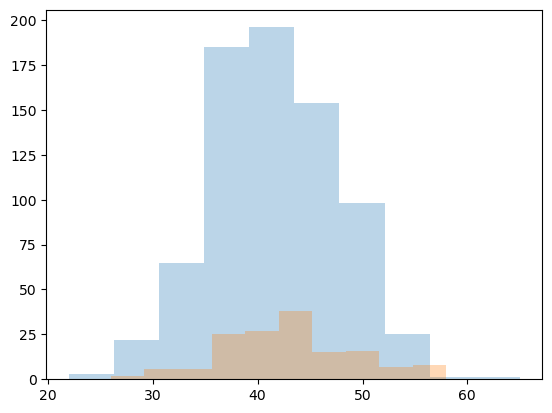

In [12]:
plt.figure()
plt.hist(df.loc[df["Churn"] == 0, ["Age"]], alpha = 0.3, bins = 10)
plt.hist(df.loc[df["Churn"] == 1, ["Age"]], alpha = 0.3, bins = 10)
plt.show()

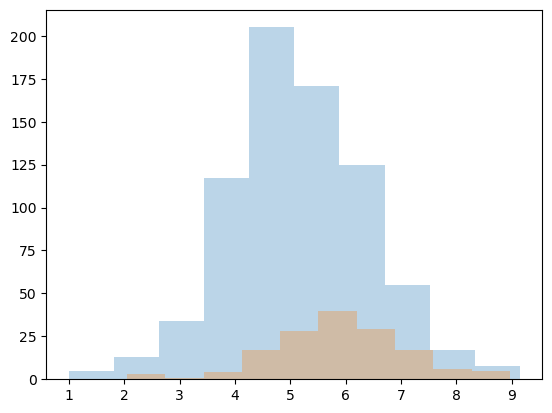

In [13]:
plt.figure()
plt.hist(df.loc[df["Churn"] == 0, ["Years"]], alpha = 0.3, bins = 10)
plt.hist(df.loc[df["Churn"] == 1, ["Years"]], alpha = 0.3, bins = 10)
plt.show()

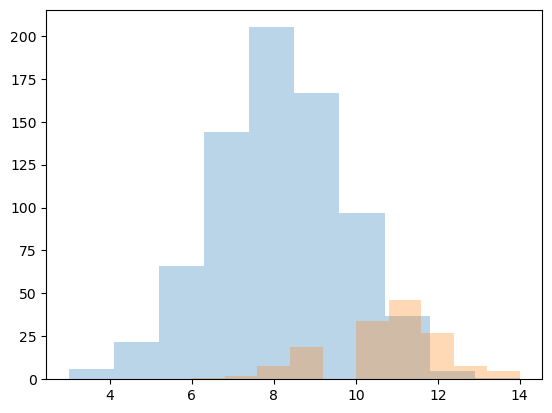

In [14]:
plt.figure()
plt.hist(df.loc[df["Churn"] == 0, ["Num_Sites"]], alpha = 0.3, bins = 10)
plt.hist(df.loc[df["Churn"] == 1, ["Num_Sites"]], alpha = 0.3, bins = 10)
plt.show()

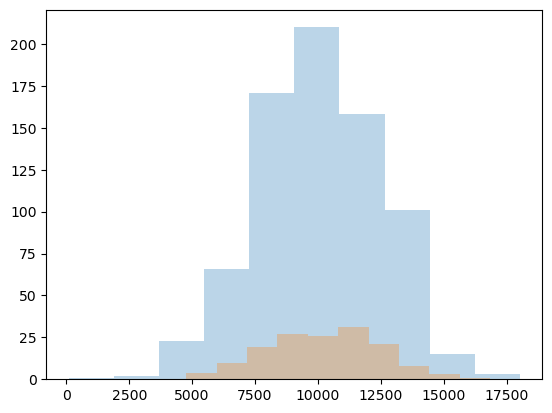

In [15]:
plt.figure()
plt.hist(df.loc[df["Churn"] == 0, ["Total_Purchase"]], alpha = 0.3, bins = 10)
plt.hist(df.loc[df["Churn"] == 1, ["Total_Purchase"]], alpha = 0.3, bins = 10)
plt.show()

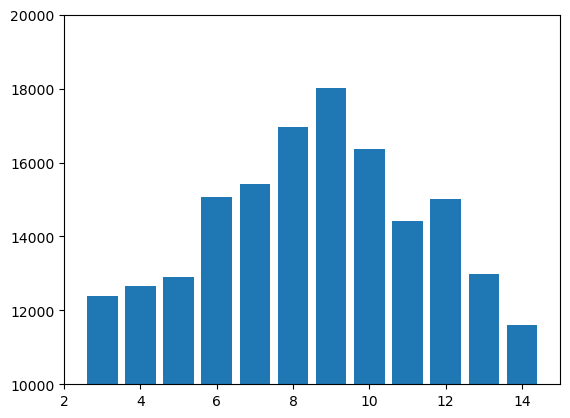

In [1718]:
plt.figure()
plt.bar(df["Num_Sites"], df["Total_Purchase"])
plt.ylim(10000, 20000)
plt.xlim(2, 15)
plt.show()

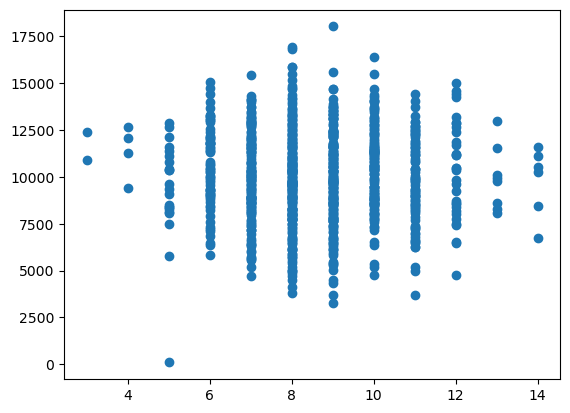

In [16]:
plt.figure()
plt.scatter(df["Num_Sites"], df["Total_Purchase"])
plt.show()

## 머신러닝용 데이터 전처리

우리는 수치형 데이터만 이용할 예정입니다. Account_Manager는 다루기 어렵지 않기 때문에 모델학습에 포함할 수도 있겠지만 무작위로 할당된 것이기 때문에 큰 의미가 없을 수 있습니다.

In [1721]:
df.head()

,Names,Age,Total_Purchase,Account_Manager,Years,Num_Sites,Onboard_date,Location,Company,Churn
0,Cameron Williams,42.0,11066.80,0,7.22,8.0,2013-08-30 07:00:40,"10265 Elizabeth Mission Barkerburgh, AK 89518",Harvey LLC,1
1,Kevin Mueller,41.0,11916.22,0,6.50,11.0,2013-08-13 00:38:46,"6157 Frank Gardens Suite 019 Carloshaven, RI 1...",Wilson PLC,1
2,Eric Lozano,38.0,12884.75,0,6.67,12.0,2016-06-29 06:20:07,"1331 Keith Court Alyssahaven, DE 90114","Miller, Johnson and Wallace",1
3,Phillip White,42.0,8010.76,0,6.71,10.0,2014-04-22 12:43:12,"13120 Daniel Mount Angelabury, WY 30645-4695",Smith Inc,1
4,Cynthia Norton,37.0,9191.58,0,5.56,9.0,2016-01-19 15:31:15,"765 Tricia Row Karenshire, MH 71730",Love-Jones,1


In [1722]:
df["year"] = df["Onboard_date"].map(lambda x : int(x[:4]))

In [1723]:
df["month"] = df["Onboard_date"].map(lambda x : int(x[5:7]))

In [1725]:
# df["day"] = df["Onboard_date"].map(lambda x : int(x[8:10]))

In [1730]:
# df["hour"] = df["Onboard_date"].map(lambda x : int(x[10:13]))

In [1732]:
# 종속 변수 원핫인코딩
df = pd.get_dummies(df, columns = ["Churn"])

In [1734]:
df.head()

,Names,Age,Total_Purchase,Account_Manager,Years,Num_Sites,Onboard_date,Location,Company,year,month,Churn_0,Churn_1
0,Cameron Williams,42.0,11066.80,0,7.22,8.0,2013-08-30 07:00:40,"10265 Elizabeth Mission Barkerburgh, AK 89518",Harvey LLC,2013,8,False,True
1,Kevin Mueller,41.0,11916.22,0,6.50,11.0,2013-08-13 00:38:46,"6157 Frank Gardens Suite 019 Carloshaven, RI 1...",Wilson PLC,2013,8,False,True
2,Eric Lozano,38.0,12884.75,0,6.67,12.0,2016-06-29 06:20:07,"1331 Keith Court Alyssahaven, DE 90114","Miller, Johnson and Wallace",2016,6,False,True
3,Phillip White,42.0,8010.76,0,6.71,10.0,2014-04-22 12:43:12,"13120 Daniel Mount Angelabury, WY 30645-4695",Smith Inc,2014,4,False,True
4,Cynthia Norton,37.0,9191.58,0,5.56,9.0,2016-01-19 15:31:15,"765 Tricia Row Karenshire, MH 71730",Love-Jones,2016,1,False,True


# 스케일링

In [1737]:
# ss = StandardScaler()
# scaled_train = ss.fit_transform(x_train)
# scaled_test = ss.transform(x_test)

In [1739]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Names            900 non-null    object 
 1   Age              900 non-null    float64
 2   Total_Purchase   900 non-null    float64
 3   Account_Manager  900 non-null    int64  
 4   Years            900 non-null    float64
 5   Num_Sites        900 non-null    float64
 6   Onboard_date     900 non-null    object 
 7   Location         900 non-null    object 
 8   Company          900 non-null    object 
 9   year             900 non-null    int64  
 10  month            900 non-null    int64  
 11  Churn_0          900 non-null    bool   
 12  Churn_1          900 non-null    bool   
dtypes: bool(2), float64(4), int64(3), object(4)
memory usage: 79.2+ KB


In [1741]:
df.columns

Index(['Names', 'Age', 'Total_Purchase', 'Account_Manager', 'Years',
       'Num_Sites', 'Onboard_date', 'Location', 'Company', 'year', 'month',
       'Churn_0', 'Churn_1'],
      dtype='object')

In [1743]:
df_2 = df[['Age', 'Total_Purchase', 'Account_Manager', 'Years', 'Num_Sites', 'year', 'month']]
df_3 = df.drop(['Age', 'Total_Purchase', 'Account_Manager', 'Years', 'Num_Sites', 'year', 'month'], axis = 1)

In [1745]:
rs = RobustScaler()
df_2_robust = rs.fit_transform(df_2)

In [1747]:
df_2 = pd.DataFrame(data = df_2_robust, columns = df_2.columns)

In [1749]:
df_2.head()

,Age,Total_Purchase,Account_Manager,Years,Num_Sites,year,month
0,0.000,0.312882,0.0,1.207831,0.000000,0.333333,0.333333
1,-0.125,0.573203,0.0,0.774096,1.000000,0.333333,0.333333
2,-0.500,0.870026,0.0,0.876506,1.333333,0.833333,0.000000
3,0.000,-0.623696,0.0,0.900602,0.666667,0.500000,-0.333333
4,-0.625,-0.261813,0.0,0.207831,0.333333,0.833333,-0.833333


In [1751]:
df_edit = pd.concat([df_2, df_3], axis = 1)

In [1753]:
df_edit.head()

,Age,Total_Purchase,Account_Manager,Years,Num_Sites,year,month,Names,Onboard_date,Location,Company,Churn_0,Churn_1
0,0.000,0.312882,0.0,1.207831,0.000000,0.333333,0.333333,Cameron Williams,2013-08-30 07:00:40,"10265 Elizabeth Mission Barkerburgh, AK 89518",Harvey LLC,False,True
1,-0.125,0.573203,0.0,0.774096,1.000000,0.333333,0.333333,Kevin Mueller,2013-08-13 00:38:46,"6157 Frank Gardens Suite 019 Carloshaven, RI 1...",Wilson PLC,False,True
2,-0.500,0.870026,0.0,0.876506,1.333333,0.833333,0.000000,Eric Lozano,2016-06-29 06:20:07,"1331 Keith Court Alyssahaven, DE 90114","Miller, Johnson and Wallace",False,True
3,0.000,-0.623696,0.0,0.900602,0.666667,0.500000,-0.333333,Phillip White,2014-04-22 12:43:12,"13120 Daniel Mount Angelabury, WY 30645-4695",Smith Inc,False,True
4,-0.625,-0.261813,0.0,0.207831,0.333333,0.833333,-0.833333,Cynthia Norton,2016-01-19 15:31:15,"765 Tricia Row Karenshire, MH 71730",Love-Jones,False,True


# 데이터셋 분류

In [1756]:
x = df_edit.drop(["Churn_0", "Churn_1", "Location", "Names", "Company", "Onboard_date"], axis = 1)
y = df_edit[["Churn_0"]]

In [1758]:
x_train, x_test, y_train, y_test = train_test_split(x, y, stratify = y, random_state = 30)

In [1760]:
x_train.head()

,Age,Total_Purchase,Account_Manager,Years,Num_Sites,year,month
236,-1.625,0.376524,1.0,-0.472892,0.000000,0.500000,-0.500000
227,0.125,-0.376521,0.0,-1.219880,0.000000,-0.166667,-0.166667
723,0.125,-0.624793,1.0,0.141566,0.000000,-0.333333,-0.333333
85,0.625,-0.812070,0.0,-0.665663,1.000000,0.500000,-0.500000
741,-0.750,-0.016050,0.0,0.834337,-0.666667,0.500000,-0.666667


# 그래한번해보자......

In [1763]:
x_train2 = x_train.copy()
y_train2 = y_train.copy()

In [1765]:
x_train2.shape

(675, 7)

In [1767]:
x_col = [f"X{i}" for i in range(1, 8)]

In [1769]:
x_col

['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7']

In [1771]:
y_col = ["y1"]

In [1773]:
# x_train2 = pd.DataFrame(x_train2)

In [1775]:
x_train2.columns = x_col
y_train2.columns = y_col

In [1777]:
x_train2.head()

,X1,X2,X3,X4,X5,X6,X7
236,-1.625,0.376524,1.0,-0.472892,0.000000,0.500000,-0.500000
227,0.125,-0.376521,0.0,-1.219880,0.000000,-0.166667,-0.166667
723,0.125,-0.624793,1.0,0.141566,0.000000,-0.333333,-0.333333
85,0.625,-0.812070,0.0,-0.665663,1.000000,0.500000,-0.500000
741,-0.750,-0.016050,0.0,0.834337,-0.666667,0.500000,-0.666667


In [1779]:
y_train2.head()

,y1
236,True
227,True
723,True
85,False
741,True


In [1781]:
x_train3, y_train3 = RandomUnderSampler(random_state = 25).fit_resample(x_train2, y_train2)

In [1783]:
print("언더샘플링 적용 전")
print(x_train2.shape, y_train2.shape)

언더샘플링 적용 전
(675, 7) (675, 1)


In [1785]:
print("언더샘플링 적용 후")
print(x_train3.shape, y_train3.shape)

언더샘플링 적용 후
(226, 7) (226, 1)


In [1787]:
print("언더샘플링 적용 전 종속 변수 분포")
print(y_train2["y1"].value_counts())

언더샘플링 적용 전 종속 변수 분포
y1
True     562
False    113
Name: count, dtype: int64


In [1789]:
print("언더샘플링 적용 후 종속 변수 분포")
print(y_train3["y1"].value_counts())

언더샘플링 적용 후 종속 변수 분포
y1
False    113
True     113
Name: count, dtype: int64


In [1791]:
x_train3.columns = x_train.columns
y_train3.columns = y_train.columns

In [1793]:
x_train3.head()

,Age,Total_Purchase,Account_Manager,Years,Num_Sites,year,month
85,0.625,-0.812070,0.0,-0.665663,1.000000,0.500000,-0.500000
139,-0.500,-0.845331,1.0,1.310241,1.000000,-0.666667,-0.333333
42,-0.750,0.134374,1.0,2.183735,0.666667,-0.500000,-0.333333
41,1.625,2.081859,1.0,0.870482,0.000000,-0.666667,0.666667
127,-0.500,1.424335,1.0,1.081325,0.666667,0.000000,0.833333


# 모델 학습

In [1795]:
logi = LogisticRegression()

In [1798]:
# y_train3 = y_train3.values

In [1800]:
logi.fit(x_train3, y_train3)

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:1339: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


LogisticRegression()

# 모델 평가

In [1803]:
print(logi.score(x_train3, y_train3))
print(logi.score(x_test, y_test))

0.8628318584070797
0.8444444444444444


# 예측

In [1806]:
test = pd.DataFrame(logi.predict(x_test))

In [1808]:
test.columns = y_test.columns

In [1810]:
test_final = test == y_test.reset_index(drop = True)

In [1812]:
test_final.value_counts()

Churn_0
True       190
False       35
Name: count, dtype: int64

In [1814]:
proba = logi.predict_proba(x_test)
print(np.round(proba, decimals = 3))

[[0.131 0.869]
 [0.071 0.929]
 [0.02  0.98 ]
 [0.196 0.804]
 [0.277 0.723]
 [0.541 0.459]
 [0.355 0.645]
 [0.235 0.765]
 [0.119 0.881]
 [0.812 0.188]
 [0.185 0.815]
 [0.531 0.469]
 [0.435 0.565]
 [0.116 0.884]
 [0.147 0.853]
 [0.057 0.943]
 [0.069 0.931]
 [0.267 0.733]
 [0.27  0.73 ]
 [0.086 0.914]
 [0.281 0.719]
 [0.347 0.653]
 [0.027 0.973]
 [0.838 0.162]
 [0.802 0.198]
 [0.497 0.503]
 [0.757 0.243]
 [0.238 0.762]
 [0.302 0.698]
 [0.099 0.901]
 [0.057 0.943]
 [0.655 0.345]
 [0.027 0.973]
 [0.084 0.916]
 [0.607 0.393]
 [0.45  0.55 ]
 [0.868 0.132]
 [0.01  0.99 ]
 [0.178 0.822]
 [0.982 0.018]
 [0.178 0.822]
 [0.027 0.973]
 [0.489 0.511]
 [0.593 0.407]
 [0.506 0.494]
 [0.811 0.189]
 [0.533 0.467]
 [0.204 0.796]
 [0.069 0.931]
 [0.06  0.94 ]
 [0.135 0.865]
 [0.917 0.083]
 [0.356 0.644]
 [0.44  0.56 ]
 [0.526 0.474]
 [0.119 0.881]
 [0.084 0.916]
 [0.069 0.931]
 [0.022 0.978]
 [0.148 0.852]
 [0.737 0.263]
 [0.033 0.967]
 [0.989 0.011]
 [0.657 0.343]
 [0.917 0.083]
 [0.347 0.653]
 [0.044 0.

In [1816]:
logi.classes_

array([False,  True])

# AUC

In [1819]:
x_test.shape

(225, 7)

In [1821]:
pred_proba = logi.predict_proba(x_test)

In [1823]:
pred_proba[:,1]

array([0.86906696, 0.92937359, 0.98037795, 0.80404387, 0.72266184,
       0.45901867, 0.64540477, 0.76488451, 0.88097719, 0.18758642,
       0.81452937, 0.46927867, 0.56521146, 0.88363175, 0.85343927,
       0.94323608, 0.93068211, 0.7332734 , 0.72996135, 0.91391233,
       0.71948808, 0.65288709, 0.97255298, 0.16213978, 0.19776429,
       0.50347308, 0.24334728, 0.76153274, 0.69766084, 0.90057281,
       0.9430539 , 0.34455433, 0.9731818 , 0.91550588, 0.39310742,
       0.54987537, 0.13175397, 0.99045168, 0.82206537, 0.01833353,
       0.8218841 , 0.97332985, 0.51095284, 0.40678161, 0.49444003,
       0.18899906, 0.46715213, 0.79641617, 0.93094659, 0.9402641 ,
       0.8649533 , 0.08290465, 0.64409925, 0.56020153, 0.47396897,
       0.88118528, 0.91582577, 0.93063485, 0.97779217, 0.85231829,
       0.26314033, 0.96711243, 0.01125088, 0.34285139, 0.08339977,
       0.65270173, 0.95581722, 0.96826447, 0.88803652, 0.85954277,
       0.80681342, 0.14389918, 0.82984779, 0.51532254, 0.31804

In [1825]:
roc_auc_score(y_test, pred_proba[:,1])

0.9426394479585969

# 예측 데이터 분석

In [1828]:
df_new = pd.read_csv("./과제/분류/new_customers.csv", index_col = None)

In [1830]:
df_new.shape

(6, 9)

In [1832]:
df_new = df_new.reset_index()

In [1834]:
df_new = df_new.iloc[:, :-1]

In [1836]:
df.columns[:9]

Index(['Names', 'Age', 'Total_Purchase', 'Account_Manager', 'Years',
       'Num_Sites', 'Onboard_date', 'Location', 'Company'],
      dtype='object')

In [1838]:
df_new.columns = df.columns[:9]

In [1840]:
df_new.head()

,Names,Age,Total_Purchase,Account_Manager,Years,Num_Sites,Onboard_date,Location,Company
0,Andrew Mccall,37.0,9935.53,1,7.71,8.0,2011-08-29 18:37:54,"38612 Johnny Stravenue Nataliebury, WI 15717-8316",King Ltd
1,Michele Wright,23.0,7526.94,1,9.28,15.0,2013-07-22 18:19:54,"21083 Nicole Junction Suite 332, Youngport, ME...",Cannon-Benson
2,Jeremy Chang,65.0,100.00,1,1.00,15.0,2006-12-11 07:48:13,"085 Austin Views Lake Julialand, WY 63726-4298",Barron-Robertson
3,Megan Ferguson,32.0,6487.50,0,9.40,14.0,2016-10-28 05:32:13,"922 Wright Branch North Cynthialand, NC 64721",Sexton-Golden
4,Taylor Young,32.0,13147.71,1,10.00,8.0,2012-03-20 00:36:46,Unit 0789 Box 0734 DPO AP 39702,Wood LLC


In [1842]:
df_new["year"] = df_new["Onboard_date"].map(lambda x : int(x[:4]))

In [1844]:
df_new["month"] = df_new["Onboard_date"].map(lambda x : int(x[5:7]))

In [1846]:
df_new.head()

,Names,Age,Total_Purchase,Account_Manager,Years,Num_Sites,Onboard_date,Location,Company,year,month
0,Andrew Mccall,37.0,9935.53,1,7.71,8.0,2011-08-29 18:37:54,"38612 Johnny Stravenue Nataliebury, WI 15717-8316",King Ltd,2011,8
1,Michele Wright,23.0,7526.94,1,9.28,15.0,2013-07-22 18:19:54,"21083 Nicole Junction Suite 332, Youngport, ME...",Cannon-Benson,2013,7
2,Jeremy Chang,65.0,100.00,1,1.00,15.0,2006-12-11 07:48:13,"085 Austin Views Lake Julialand, WY 63726-4298",Barron-Robertson,2006,12
3,Megan Ferguson,32.0,6487.50,0,9.40,14.0,2016-10-28 05:32:13,"922 Wright Branch North Cynthialand, NC 64721",Sexton-Golden,2016,10
4,Taylor Young,32.0,13147.71,1,10.00,8.0,2012-03-20 00:36:46,Unit 0789 Box 0734 DPO AP 39702,Wood LLC,2012,3


In [1848]:
df_new_pred = df_new[["Age", "Total_Purchase", "Account_Manager", "Years", "Num_Sites", "year", "month"]]

In [1850]:
df_new_pred.head()

,Age,Total_Purchase,Account_Manager,Years,Num_Sites,year,month
0,37.0,9935.53,1,7.71,8.0,2011,8
1,23.0,7526.94,1,9.28,15.0,2013,7
2,65.0,100.00,1,1.00,15.0,2006,12
3,32.0,6487.50,0,9.40,14.0,2016,10
4,32.0,13147.71,1,10.00,8.0,2012,3


# 예측 데이터 스케일링

In [1853]:
df_new_pred = rs.transform(df_new_pred)

In [1855]:
df_new_pred

array([[-0.625     , -0.03381569,  1.        ,  1.50301205,  0.        ,
         0.        ,  0.33333333],
       [-2.375     , -0.77197165,  1.        ,  2.44879518,  2.33333333,
         0.33333333,  0.16666667],
       [ 2.875     , -3.04809174,  1.        , -2.53915663,  2.33333333,
        -0.83333333,  1.        ],
       [-1.25      , -1.09052684,  0.        ,  2.52108434,  2.        ,
         0.83333333,  0.66666667],
       [-1.25      ,  0.95061497,  1.        ,  2.88253012,  0.        ,
         0.16666667, -0.5       ],
       [-2.5       , -0.49053588,  1.        , -1.05722892,  2.        ,
         0.        , -0.66666667]])

# 예측 데이터 예측

In [1858]:
result = logi.predict(df_new_pred)

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


In [1860]:
result

array([ True, False, False, False,  True, False])

In [1862]:
df_new["Churn_0"] = result

In [1864]:
df_new["Churn_pred"] = df_new["Churn_0"].map(lambda x : 0 if x == True else 1)

In [1866]:
df_new = df_new.drop("Churn_0", axis = 1)

In [1868]:
df_new.head()

,Names,Age,Total_Purchase,Account_Manager,Years,Num_Sites,Onboard_date,Location,Company,year,month,Churn_pred
0,Andrew Mccall,37.0,9935.53,1,7.71,8.0,2011-08-29 18:37:54,"38612 Johnny Stravenue Nataliebury, WI 15717-8316",King Ltd,2011,8,0
1,Michele Wright,23.0,7526.94,1,9.28,15.0,2013-07-22 18:19:54,"21083 Nicole Junction Suite 332, Youngport, ME...",Cannon-Benson,2013,7,1
2,Jeremy Chang,65.0,100.00,1,1.00,15.0,2006-12-11 07:48:13,"085 Austin Views Lake Julialand, WY 63726-4298",Barron-Robertson,2006,12,1
3,Megan Ferguson,32.0,6487.50,0,9.40,14.0,2016-10-28 05:32:13,"922 Wright Branch North Cynthialand, NC 64721",Sexton-Golden,2016,10,1
4,Taylor Young,32.0,13147.71,1,10.00,8.0,2012-03-20 00:36:46,Unit 0789 Box 0734 DPO AP 39702,Wood LLC,2012,3,0
